# Прогнозирование оформления срочного вклада клиентом банка

## Описание проекта

**Цель.** Построить модель бинарной классификации, которая по данным о клиенте и истории контактов предсказывает, оформит ли клиент срочный вклад (`y` = yes / no) после телефонного маркетингового звонка.

**Зачем это банку.** Модель ранжирует клиентов по вероятности согласия, поэтому банк может тратить меньше звонков на тех, кто вряд ли согласится.

### Данные

- Источник: результаты кампаний прямого маркетинга португальского банка (датасет *Bank Marketing*, UCI); записи упорядочены по дате, 2008–2010 гг.
- Файл `bank.csv`: **45 211** записей, **16** входных признаков и целевая переменная `y`.
- Расширенный набор `bank-additional.csv` в этой работе не используется.

| Группа признаков | Признаки |
|---|---|
| Клиент | `age`, `job`, `marital`, `education`, `default`, `balance`, `housing`, `loan` |
| Последний контакт | `contact`, `day`, `month`, `duration` |
| Прочие | `campaign`, `pdays`, `previous`, `poutcome` |

### Особенности задачи

1. **Дисбаланс классов:** согласившихся клиентов около 12% (11,7% в тестовой выборке).
2. **Утечка данных:** `duration` известна только после звонка, поэтому исключена из признаков.
3. **Неравная цена ошибок:** пропущенный потенциальный клиент (FN) обходится дороже лишнего звонка (FP), поэтому основная метрика — **recall** по классу «yes».

### Метрики

- **Recall** — основная метрика.
- **ROC-AUC** — качество ранжирования независимо от порога.
- Дополнительно: precision, F1, PR-AUC.
- **Accuracy не используется:** модель, всегда отвечающая «no», получила бы около 88%.

### План работы

1. Загрузка данных и EDA
2. Предобработка и разбиение выборки
3. Базовая модель: LogisticRegression
4. CatBoost + Optuna
5. Нейросеть Keras + Optuna
6. Сравнение моделей и общие выводы

**Стек:** Python, pandas, scikit-learn, CatBoost, Keras, Optuna.

## 1. Подготовка окружения

Работа выполнена на Python 3.11.7. Список зависимостей сохранен в файл `requirements.txt` , установить их можно командой `pip install -r requirements.txt`.

Импортируем библиотеки и фиксируем `RANDOM_STATE`. Разбиение данных, инициализация весов нейросети и подбор гиперпараметров должны воспроизводиться при повторном запуске.

In [1]:
#%pip install -q -r requirements.txt

In [2]:
import os
import random
import time
import optuna
import keras
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from keras import layers, regularizers

from itertools import product

import seaborn as sns

from data_profiling import ProfileReport

from catboost import CatBoostClassifier, Pool

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (fbeta_score, recall_score, precision_score, f1_score,
                             roc_auc_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report, 
                             roc_curve, precision_recall_curve)

RANDOM_STATE = 230325
pd.set_option('display.max_rows', None)      # показывать все строки
pd.set_option('display.max_columns', None)   # показывать все столбцы
os.environ["PYTHONHASHSEED"] = str(RANDOM_STATE)
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
%matplotlib inline
optuna.logging.set_verbosity(optuna.logging.WARNING)
keras.utils.set_random_seed(RANDOM_STATE)

## 2. Загрузка данных

Функция `load_csv` читает файл (разделитель `;`) и сразу выводит:

- первые строки;
- размер таблицы и типы данных;
- число пропусков и полных дубликатов.

Это базовая проверка качества данных перед анализом.

In [3]:
def load_csv(path, sep = None):
    if os.path.exists(path):
        df = pd.read_csv(path, sep = sep)
    else:
        print('Something is wrong')
        
    display(df.head(10))  
    print('Размер датафрейма:')
    display(df.shape)
    print('Тип данных:')
    display(df.dtypes)
    print('Количество пропусков:')
    display(df.isna().sum())
    print('Количество полных дубликатов:', df.duplicated().sum())
    return df

In [4]:
df = load_csv('./datasets/bank.csv', sep = ';')

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
5,35,management,married,tertiary,no,231,yes,no,unknown,5,may,139,1,-1,0,unknown,no
6,28,management,single,tertiary,no,447,yes,yes,unknown,5,may,217,1,-1,0,unknown,no
7,42,entrepreneur,divorced,tertiary,yes,2,yes,no,unknown,5,may,380,1,-1,0,unknown,no
8,58,retired,married,primary,no,121,yes,no,unknown,5,may,50,1,-1,0,unknown,no
9,43,technician,single,secondary,no,593,yes,no,unknown,5,may,55,1,-1,0,unknown,no


Размер датафрейма:


(45211, 17)

Тип данных:


age           int64
job          object
marital      object
education    object
default      object
balance       int64
housing      object
loan         object
contact      object
day           int64
month        object
duration      int64
campaign      int64
pdays         int64
previous      int64
poutcome     object
y            object
dtype: object

Количество пропусков:


age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Количество полных дубликатов: 0


### Выводы

- В таблице **45 211** записей и **17** столбцов: 7 числовых и 10 категориальных (включая целевой `y`).
- Явных пропусков и полных дубликатов **нет**.
- В `job`, `education`, `contact` и `poutcome` встречается значение `unknown`, которое по смыслу является пропуском. Оставляем его отдельной категорией, чтобы не терять информацию.

## 3. Разведочный анализ данных (EDA)

Строим автоматический отчёт `ProfileReport` (распределения, корреляции, предупреждения о данных) и дополняем его проверкой баланса классов и конверсии по категориям.

**Цель:** понять, какие преобразования нужны перед моделированием.

In [5]:
profile = ProfileReport(df, title="Bank Marketing")

In [ ]:
#profile.to_file('profile.html')
#profile.to_notebook_iframe()

### Выводы по EDA

- **Дисбаланс:** доля «yes» — [11.7]%. Поэтому используем веса классов и метрики recall / ROC-AUC / F1.
- **Пропуски в виде `unknown`:** `contact` — 28.8%, `poutcome` — 81.7%, `education` — 4.1%, `job` — 0.6%.
- **Выбросы и хвосты:** у `balance`, `campaign`, `previous` длинные правые хвосты, у `balance` есть отрицательные значения → логарифмирование для линейной модели и нейросети.
- **`pdays = -1`:** у 81.7% клиентов; это метка «ранее не контактировали», а не число дней.
- **Конверсия по категориям** заметно различается по `month`, `contact` и `poutcome` (максимальна после успешной прошлой кампании) → ожидаем, что эти признаки будут важными.

## 4. Предобработка данных и разбиение выборки

### Решения по признакам

| Решение | Почему |
|---|---|
| Удаляем `duration` | Утечка данных: известна только после звонка |
| Удаляем `day` | Малоинформативен, склонен вызывать переобучение |
| Добавляем `negative_balance` (`balance <= 0`) | Нулевой и отрицательный баланс может означать иное поведение клиента |
| Добавляем `was_previous_campaign` (`pdays != -1`) | Явный признак участия в прошлой кампании |
| Заменяем `pdays = -1` медианой (по train) | `-1` — метка, а не число дней |
| Логарифмируем `balance` (со знаком) и `campaign` | Убираем тяжёлые хвосты и влияние выбросов |
| Масштабируем числовые, кодируем категориальные one-hot | Нужно для линейной модели и нейросети |

### Разбиение

- Train / test = 80 / 20 со стратификацией по `y`.
- Все преобразования обучаются **только на train** внутри пайплайна, поэтому данные теста не влияют на обучение (нет утечки).
- Для CatBoost категориальные признаки передаются как есть.

In [7]:
# Целевая переменная и удаление признаков
y = (df['y'] == 'yes').astype(int)
# duration: утечка данных (известна только после звонка), day: малоинформативен
X = df.drop(columns=['y', 'target', 'duration', 'day'], errors='ignore')

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

# Новые бинарные признаки (без обучения, поэтому безопасно делать до разбиения на фолды)
def add_features(data):
    data = data.copy()
    data['negative_balance'] = (data['balance'] <= 0).astype(int)
    data['was_previous_campaign'] = (data['pdays'] != -1).astype(int)
    return data

# Логарифм, устойчивый к нулям и отрицательным значениям (для balance)
def signed_log1p(x):
    return np.sign(x) * np.log1p(np.abs(x))

# Группы признаков
log_signed_cols = ['balance']
log_cols = ['campaign']
pdays_col = ['pdays']
num_cols = ['age', 'previous']
binary_new = ['negative_balance', 'was_previous_campaign']
binary_cat = ['default', 'housing', 'loan']
cat_cols = ['job', 'marital', 'education', 'contact', 'month', 'poutcome']

preprocessor = ColumnTransformer([
    ('balance_log', Pipeline([
        ('log', FunctionTransformer(signed_log1p)),
        ('scale', StandardScaler())]), log_signed_cols),
    ('campaign_log', Pipeline([
        ('log', FunctionTransformer(np.log1p)),
        ('scale', StandardScaler())]), log_cols),
    # -1 считается "пропуском", заменяется медианой остальных значений train
    ('pdays', Pipeline([
        ('impute', SimpleImputer(missing_values=-1, strategy='median')),
        ('scale', StandardScaler())]), pdays_col),
    ('num', StandardScaler(), num_cols),
    ('bin_new', 'passthrough', binary_new),
    ('bin_cat', OneHotEncoder(drop='if_binary', handle_unknown='ignore'), binary_cat),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
])

### Результат разбиения

- Train: **36 168** записей, test: **9 043**.
- Доля «yes» в обеих выборках сохранена благодаря стратификации.
- Тестовая выборка не используется до финальной оценки моделей.

## 5. Базовая модель: LogisticRegression

**Что делаем.** Обучаем простую интерпретируемую модель: она задаёт нижнюю границу качества, с которой сравниваем остальные.

**Ключевые настройки**

- `class_weight='balanced'` — ошибки на редком классе «yes» штрафуются сильнее, и модель не скатывается к ответу «no» для всех.
- Предобработка (логарифмы, масштабирование, one-hot) входит в единый `Pipeline`, поэтому на тесте повторяется без утечки данных.


Test recall   : 0.6682
Test precision: 0.2681
Test F1       : 0.3827
Test ROC-AUC  : 0.7799


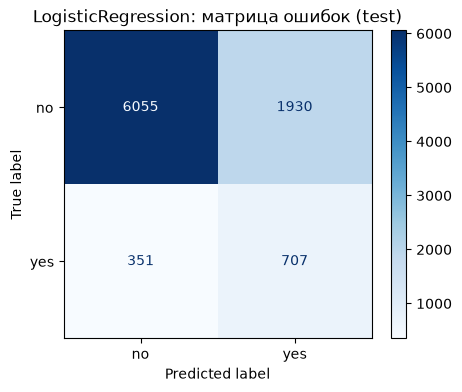

In [8]:
log_reg = Pipeline([
    ('features', FunctionTransformer(add_features)),
    ('prep', preprocessor),
    ('clf', LogisticRegression(class_weight='balanced', max_iter=1000,
                               random_state=RANDOM_STATE)),
])

# Оценка на тесте
log_reg.fit(X_train, y_train)

y_pred = log_reg.predict(X_test)
y_proba = log_reg.predict_proba(X_test)[:, 1]
proba_lr = y_proba

print('\nTest recall   :', round(recall_score(y_test, y_pred), 4))
print('Test precision:', round(precision_score(y_test, y_pred), 4))
print('Test F1       :', round(f1_score(y_test, y_pred), 4))
print('Test ROC-AUC  :', round(roc_auc_score(y_test, y_proba), 4))

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=['no', 'yes']).plot(ax=ax, cmap='Blues', values_format='d')
ax.set_title('LogisticRegression: матрица ошибок (test)')
plt.show()

### Результаты на тесте

| Recall | Precision | F1 | ROC-AUC |
|---|---|---|---|
| **0,668** | 0,268 | 0,383 | 0,780 |

Матрица ошибок: TN = 6 055, FP = 1 930, FN = 351, TP = 707.

### Выводы

- Модель находит **707 из 1 058** согласившихся клиентов (67%).
- Цена этого — **1 930** ложных срабатываний: из каждых четырёх предсказанных «yes» верен примерно один.
- Чтобы охватить две трети заинтересованных клиентов, пришлось бы обзвонить около **29%** базы.
- Самый высокий recall среди трёх моделей, но и самые низкие precision и ROC-AUC. Линейная модель, вероятно, не улавливает нелинейные зависимости и взаимодействия признаков (например, месяц × способ связи).

## 6. CatBoost с подбором гиперпараметров (Optuna)

**Почему CatBoost.** Градиентный бустинг над деревьями хорошо работает на табличных данных со смешанными признаками: CatBoost сам обрабатывает категориальные признаки и нелинейности.

**Подготовка данных**

- Логарифмы и масштабирование не нужны: деревья инвариантны к монотонным преобразованиям.
- Новые признаки и замена `pdays = -1` медианой — те же, что для логистической регрессии.
- Из train выделяем валидационную часть (80 / 20): по ней работают ранняя остановка и подбор гиперпараметров. **Тест остаётся нетронутым.**

In [9]:
cat_features = ['job', 'marital', 'education', 'default', 'housing',
                'loan', 'contact', 'month', 'poutcome']

# Те же признаки, что и для LogisticRegression: negative_balance, was_previous_campaign,
# Логарифмы и масштабирование не нужны - деревья инвариантны к монотонным преобразованиям признаков.
pdays_median = X_train.loc[X_train['pdays'] != -1, 'pdays'].median()

def prep_catboost(data):
    data = add_features(data)
    data['pdays'] = data['pdays'].replace(-1, pdays_median)
    return data

X_tr_full = prep_catboost(X_train)
X_te = prep_catboost(X_test)

# Отдельная валидационная часть train: для early stopping и целевой метрики Optuna.
# Test не трогаем до самого конца.
X_tr, X_val, y_tr, y_val = train_test_split(
    X_tr_full, y_train, test_size=0.2, stratify=y_train, random_state=RANDOM_STATE
)

# Pool создаётся один раз и переиспользуется во всех trial'ах (экономит время)
train_pool = Pool(X_tr, y_tr, cat_features=cat_features)
val_pool = Pool(X_val, y_val, cat_features=cat_features)

### Схема подбора гиперпараметров

**Основные параметры** (сильнее всего влияют на модель) задаём сеткой — получается 6 отдельных моделей:

- `depth` ∈ {4, 6, 8}
- `auto_class_weights` ∈ {Balanced, SqrtBalanced}

**Второстепенные параметры** внутри каждой модели подбирает Optuna: `learning_rate`, `l2_leaf_reg`, `random_strength`, `bagging_temperature`.

**Как ограничено время обучения**

- ранняя остановка: 50 итераций без улучшения AUC;
- не более 600 деревьев;
- 15 попыток (trials) на модель.

**Целевая метрика Optuna — F2** (recall важнее precision в 4 раза). Чистый recall при пороге 0,5 можно «накрутить», предсказывая «yes» почти всем; F2 такое поведение штрафует.

In [10]:
# Основные параметры: фиксируем сеткой, каждая комбинация = отдельная модель
MAIN_GRID = {
    'depth': [4, 6, 8],
    'auto_class_weights': ['Balanced', 'SqrtBalanced'],
}
configs = [dict(zip(MAIN_GRID, v)) for v in product(*MAIN_GRID.values())]

# Параметры, ограничивающие время обучения
N_TRIALS = 15            # trial'ов на каждую модель
TIMEOUT_PER_MODEL = 180  # секунд на одно исследование Optuna
MAX_ITERS = 600          # потолок числа деревьев 

def make_objective(main_params): # Внутри каждой конфигурации Optuna подбирает второстепенные числовые параметры
    def objective(trial):
        tuned = dict(
            learning_rate=trial.suggest_float('learning_rate', 0.03, 0.3, log=True),
            l2_leaf_reg=trial.suggest_float('l2_leaf_reg', 1, 20, log=True),
            random_strength=trial.suggest_float('random_strength', 0.1, 5, log=True),
            bagging_temperature=trial.suggest_float('bagging_temperature', 0, 3),
        )
        model = CatBoostClassifier(
            **main_params, **tuned,
            bootstrap_type='Bayesian',
            iterations=MAX_ITERS,
            eval_metric='AUC',
            early_stopping_rounds=50,
            random_seed=RANDOM_STATE,
            thread_count=-1,
            verbose=False,
        )
        model.fit(train_pool, eval_set=val_pool)

        proba = model.predict_proba(X_val)[:, 1]
        pred = (proba >= 0.5).astype(int)
        trial.set_user_attr('best_iteration', model.get_best_iteration())
        trial.set_user_attr('recall', recall_score(y_val, pred))
        trial.set_user_attr('roc_auc', roc_auc_score(y_val, proba))
        return fbeta_score(y_val, pred, beta=2)   # recall весит в 4 раза больше precision
    return objective

results = []
for cfg in configs:
    t0 = time.time()
    study = optuna.create_study(
        direction='maximize',
        sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
    )
    study.optimize(make_objective(cfg), n_trials=N_TRIALS, timeout=TIMEOUT_PER_MODEL)
    b = study.best_trial
    results.append({
        **cfg,
        'F2_val': b.value,
        'recall_val': b.user_attrs['recall'],
        'roc_auc_val': b.user_attrs['roc_auc'],
        'best_iteration': b.user_attrs['best_iteration'],
        'n_trials': len(study.trials),
        'time_s': round(time.time() - t0, 1),
        'best_params': b.params,
    })
    print(f"{cfg} -> F2={b.value:.4f}, recall={b.user_attrs['recall']:.4f}, "
          f"AUC={b.user_attrs['roc_auc']:.4f}, {time.time() - t0:.0f}s")

results_df = pd.DataFrame(results).sort_values('F2_val', ascending=False).reset_index(drop=True)
results_df.drop(columns='best_params')

{'depth': 4, 'auto_class_weights': 'Balanced'} -> F2=0.5408, recall=0.6418, AUC=0.7970, 52s
{'depth': 4, 'auto_class_weights': 'SqrtBalanced'} -> F2=0.4620, recall=0.4539, AUC=0.7939, 60s
{'depth': 6, 'auto_class_weights': 'Balanced'} -> F2=0.5365, recall=0.6371, AUC=0.7914, 51s
{'depth': 6, 'auto_class_weights': 'SqrtBalanced'} -> F2=0.4665, recall=0.4586, AUC=0.7973, 70s
{'depth': 8, 'auto_class_weights': 'Balanced'} -> F2=0.5430, recall=0.6300, AUC=0.7965, 65s
{'depth': 8, 'auto_class_weights': 'SqrtBalanced'} -> F2=0.4603, recall=0.4504, AUC=0.7931, 74s


,depth,auto_class_weights,F2_val,recall_val,roc_auc_val,best_iteration,n_trials,time_s
0,8,Balanced,0.542991,0.630024,0.796536,96,15,65.4
1,4,Balanced,0.540837,0.641844,0.796960,73,15,51.6
2,6,Balanced,0.536532,0.637116,0.791395,19,15,50.5
3,6,SqrtBalanced,0.466458,0.458629,0.797324,82,15,70.1
4,4,SqrtBalanced,0.461983,0.453901,0.793894,176,15,59.5
5,8,SqrtBalanced,0.460256,0.450355,0.793063,54,15,74.4


### Результаты подбора (валидация)

| Параметр | Что наблюдаем |
|---|---|
| Веса классов | `Balanced`: F2 = 0,537–0,543, recall 0,63–0,64. `SqrtBalanced`: F2 = 0,460–0,467, recall 0,45–0,46 |
| ROC-AUC | почти одинаков у всех моделей: 0,791–0,797 |
| Глубина | 4 / 6 / 8 почти не влияет (разброс F2 при `Balanced` ≈ 0,007) |

**Лучшая конфигурация:** `depth = 8`, `Balanced`; `learning_rate` ≈ 0,048, `l2_leaf_reg` ≈ 2,98, `random_strength` ≈ 0,10, `bagging_temperature` ≈ 1,44; ранняя остановка на 96-й итерации. Обучение одной конфигурации — 40–60 с.

### Выводы

- Главный эффект даёт **схема весов классов**: она сдвигает баланс recall / precision, но не качество ранжирования клиентов (ROC-AUC не меняется).
- Выбор `depth = 8` вместо более простого `depth = 4` — в пределах шума.

Лучшая конфигурация:
depth                        8
auto_class_weights    Balanced
F2_val                0.542991
recall_val            0.630024
roc_auc_val           0.796536
best_iteration              96
n_trials                    15
time_s                    65.4
Подобранные параметры: {'learning_rate': 0.0482496203011174, 'l2_leaf_reg': 2.9820342349277658, 'random_strength': 0.10268627786170409, 'bagging_temperature': 1.4374709933176935}

Test recall   : 0.6418
Test precision: 0.306
Test F1       : 0.4144
Test ROC-AUC  : 0.7908


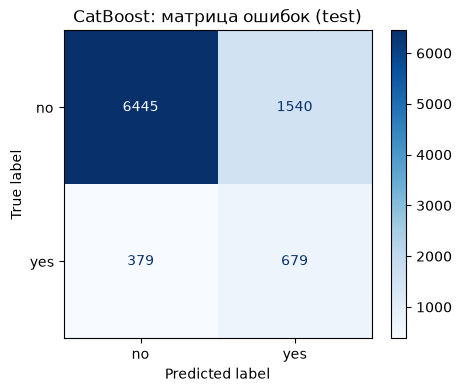

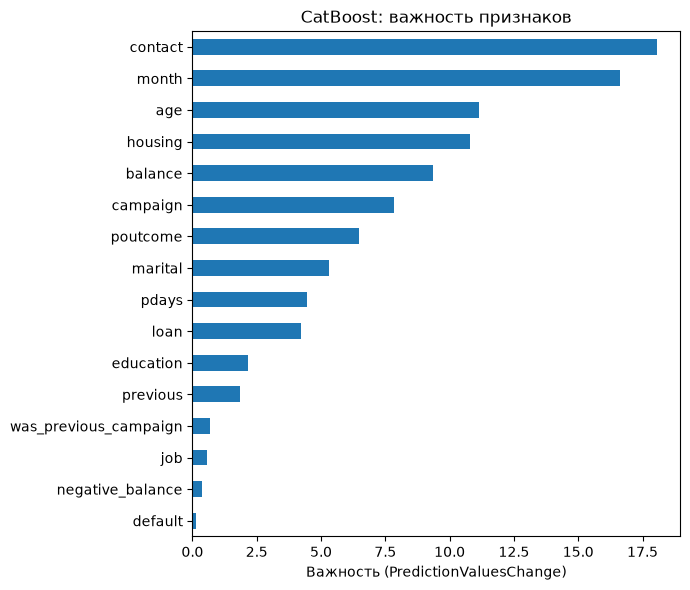

In [11]:
best = results_df.iloc[0]
print('Лучшая конфигурация:')
print(best.drop('best_params').to_string())
print('Подобранные параметры:', best['best_params'])

# Дообучаем на всей обучающей выборке (train без отдельной валидации).
# Число деревьев берём из early stopping с небольшим запасом на увеличенный объём данных.
final_model = CatBoostClassifier(
    depth=int(best['depth']),
    auto_class_weights=best['auto_class_weights'],
    **best['best_params'],
    bootstrap_type='Bayesian',
    iterations=int(best['best_iteration'] * 1.1) + 1,
    random_seed=RANDOM_STATE,
    thread_count=-1,
    verbose=False,
)
final_model.fit(X_tr_full, y_train, cat_features=cat_features)

# Оценка на тесте
y_pred = final_model.predict(X_te)
y_proba = final_model.predict_proba(X_te)[:, 1]
proba_cb = y_proba


print('\nTest recall   :', round(recall_score(y_test, y_pred), 4))
print('Test precision:', round(precision_score(y_test, y_pred), 4))
print('Test F1       :', round(f1_score(y_test, y_pred), 4))
print('Test ROC-AUC  :', round(roc_auc_score(y_test, y_proba), 4))

# Матрица ошибок
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=['no', 'yes']).plot(ax=ax, cmap='Blues', values_format='d')
ax.set_title('CatBoost: матрица ошибок (test)')
plt.show()

# Важность признаков
imp = pd.Series(final_model.get_feature_importance(), index=X_tr_full.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 6))
imp.plot.barh(ax=ax)
ax.set_title('CatBoost: важность признаков')
ax.set_xlabel('Важность (PredictionValuesChange)')
plt.tight_layout()
plt.show()

### Результаты на тесте

| Recall | Precision | F1 | ROC-AUC |
|---|---|---|---|
| 0,642 | **0,306** | 0,414 | 0,791 |

Матрица ошибок: TN = 6 445, FP = 1 540, FN = 379, TP = 679.

### Выводы

**Сравнение с LogisticRegression**

- ROC-AUC выше на 0,011, precision — на 0,04, F1 — на 0,03.
- Ложных срабатываний на 390 меньше, но пропущенных клиентов на 28 больше (recall ниже на 0,026).

**Важность признаков**

- Наибольший вклад у `contact`, `month`, `age`, `housing`, `balance`, `campaign`, `poutcome`.
- Построенные признаки (`was_previous_campaign`, `negative_balance`) и `default` почти не важны: их информация в основном дублируется `pdays` / `poutcome` и `balance`.

## 7. Нейросеть (Keras) с подбором гиперпараметров (Optuna)

**Подготовка данных**

- Нейросети нужны числовые признаки, поэтому используем тот же препроцессинг, что для логистической регрессии (логарифмы, масштабирование, one-hot): на выходе **48** признаков.
- Валидационное разбиение то же, что у CatBoost (одинаковые `random_state` и стратификация), поэтому модели сопоставимы.
- Дисбаланс учитываем весами классов `balanced`.

**Число нейронов** считается автоматически: ближайшая степень двойки, не меньшая числа входов (**64**); второй слой вдвое меньше (**32**).

In [12]:
# Тот же препроцессинг, что и для LogisticRegression (логарифмы, масштабирование, one-hot)
prep_template = Pipeline([
    ('features', FunctionTransformer(add_features)),
    ('prep', preprocessor),
])

def to_dense32(m):
    return (m.toarray() if hasattr(m, 'toarray') else np.asarray(m)).astype('float32')

# Валидация: то же разбиение, что и для CatBoost (одинаковые random_state и stratify)
X_tr_raw, X_val_raw, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=RANDOM_STATE
)

prep_tr = clone(prep_template)                 # обучается только на train-части
X_tr_np = to_dense32(prep_tr.fit_transform(X_tr_raw))
X_val_np = to_dense32(prep_tr.transform(X_val_raw))
y_tr_np, y_val_np = y_tr.values, y_val.values

INPUT_DIM = X_tr_np.shape[1]
UNITS_1 = 1 << (INPUT_DIM - 1).bit_length()    # ближайшая степень двойки >= числа входов
UNITS_2 = UNITS_1 // 2
print(f'Входных признаков: {INPUT_DIM}; нейронов в слоях: {UNITS_1} -> {UNITS_2}')

# Веса классов 'balanced' (как у LogisticRegression)
n_pos = y_tr_np.sum(); n_neg = len(y_tr_np) - n_pos
CLASS_WEIGHT = {0: len(y_tr_np) / (2 * n_neg), 1: len(y_tr_np) / (2 * n_pos)}

Входных признаков: 48; нейронов в слоях: 64 -> 32


### Схема подбора гиперпараметров

**Основные параметры** задаём сеткой — 8 архитектур:

- число скрытых слоёв: 1 или 2;
- использование Dropout;
- использование BatchNormalization.

**Второстепенные параметры** подбирает Optuna: `learning_rate`, `l2`-регуляризация, `batch_size` и (при включённом Dropout) доля отключаемых нейронов.

**Как ограничено время обучения:** ранняя остановка по `val_auc` (patience = 5), крупные батчи, 20 попыток (trials) на архитектуру.

**Целевая метрика** — F2, как и для CatBoost.

In [13]:
def build_model(input_dim, n_layers, use_dropout, use_bn, lr, dropout_rate, l2):
    units = [UNITS_1 // (2 ** i) for i in range(n_layers)]   # 1 слой: [64]; 2 слоя: [64, 32]
    inputs = keras.Input(shape=(input_dim,))
    x = inputs
    for u in units:
        x = layers.Dense(u, use_bias=not use_bn,
                         kernel_regularizer=regularizers.l2(l2))(x)
        if use_bn:
            x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
        if use_dropout:
            x = layers.Dropout(dropout_rate)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)
    model = keras.Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss='binary_crossentropy',
                  metrics=[keras.metrics.AUC(name='auc')])
    return model

# Основные параметры: сетка (8 моделей)
MAIN_GRID = {
    'n_layers': [1, 2],
    'use_dropout': [False, True],
    'use_bn': [False, True],
}
configs = [dict(zip(MAIN_GRID, v)) for v in product(*MAIN_GRID.values())]

N_TRIALS = 10
TIMEOUT_PER_MODEL = 150     # секунд на одно исследование Optuna
MAX_EPOCHS = 60

def make_objective(main):
    def objective(trial):
        keras.backend.clear_session()
        keras.utils.set_random_seed(RANDOM_STATE)

        lr = trial.suggest_float('learning_rate', 5e-4, 1e-2, log=True)
        l2 = trial.suggest_float('l2', 1e-6, 1e-2, log=True)
        batch_size = trial.suggest_categorical('batch_size', [256, 512, 1024])
        dropout_rate = (trial.suggest_float('dropout_rate', 0.1, 0.5)
                        if main['use_dropout'] else 0.0)

        model = build_model(INPUT_DIM, main['n_layers'], main['use_dropout'],
                            main['use_bn'], lr, dropout_rate, l2)
        early = keras.callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=5,
                                              restore_best_weights=True)
        hist = model.fit(X_tr_np, y_tr_np, validation_data=(X_val_np, y_val_np),
                         epochs=MAX_EPOCHS, batch_size=batch_size,
                         class_weight=CLASS_WEIGHT, callbacks=[early], verbose=0)

        proba = model.predict(X_val_np, batch_size=4096, verbose=0).ravel()
        pred = (proba >= 0.5).astype(int)
        trial.set_user_attr('best_epoch', int(np.argmax(hist.history['val_auc'])) + 1)
        trial.set_user_attr('recall', recall_score(y_val_np, pred))
        trial.set_user_attr('roc_auc', roc_auc_score(y_val_np, proba))
        return fbeta_score(y_val_np, pred, beta=2)     # та же метрика, что и для CatBoost
    return objective

results = []
for cfg in configs:
    t0 = time.time()
    study = optuna.create_study(direction='maximize',
                                sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    study.optimize(make_objective(cfg), n_trials=N_TRIALS, timeout=TIMEOUT_PER_MODEL)
    b = study.best_trial
    results.append({
        **cfg,
        'F2_val': b.value,
        'recall_val': b.user_attrs['recall'],
        'roc_auc_val': b.user_attrs['roc_auc'],
        'best_epoch': b.user_attrs['best_epoch'],
        'n_trials': len(study.trials),
        'time_s': round(time.time() - t0, 1),
        'best_params': b.params,
    })
    print(f"{cfg} -> F2={b.value:.4f}, recall={b.user_attrs['recall']:.4f}, "
          f"AUC={b.user_attrs['roc_auc']:.4f}, {time.time() - t0:.0f}s")

results_nn = pd.DataFrame(results).sort_values('F2_val', ascending=False).reset_index(drop=True)
results_nn.drop(columns='best_params')


{'n_layers': 1, 'use_dropout': False, 'use_bn': False} -> F2=0.5312, recall=0.6525, AUC=0.7939, 34s
{'n_layers': 1, 'use_dropout': False, 'use_bn': True} -> F2=0.5264, recall=0.6525, AUC=0.7896, 27s
{'n_layers': 1, 'use_dropout': True, 'use_bn': False} -> F2=0.5326, recall=0.6726, AUC=0.7876, 37s
{'n_layers': 1, 'use_dropout': True, 'use_bn': True} -> F2=0.5254, recall=0.6820, AUC=0.7912, 33s
{'n_layers': 2, 'use_dropout': False, 'use_bn': False} -> F2=0.5245, recall=0.6407, AUC=0.7914, 30s
{'n_layers': 2, 'use_dropout': False, 'use_bn': True} -> F2=0.5235, recall=0.5946, AUC=0.7929, 32s
{'n_layers': 2, 'use_dropout': True, 'use_bn': False} -> F2=0.5321, recall=0.6537, AUC=0.7875, 46s
{'n_layers': 2, 'use_dropout': True, 'use_bn': True} -> F2=0.5319, recall=0.6466, AUC=0.7917, 45s


,n_layers,use_dropout,use_bn,F2_val,recall_val,roc_auc_val,best_epoch,n_trials,time_s
0,1,True,False,0.532572,0.672577,0.787627,43,10,37.0
1,2,True,False,0.532140,0.653664,0.787508,37,10,46.0
2,2,True,True,0.531894,0.646572,0.791710,7,10,45.0
3,1,False,False,0.531178,0.652482,0.793878,44,10,33.8
4,1,False,True,0.526416,0.652482,0.789616,28,10,27.3
5,1,True,True,0.525405,0.682033,0.791193,19,10,33.2
6,2,False,False,0.524482,0.640662,0.791413,26,10,30.4
7,2,False,True,0.523522,0.594563,0.792860,11,10,31.6


### Результаты подбора (валидация)

- Все 8 архитектур близки: F2 = 0,524–0,534, ROC-AUC = 0,788–0,795.
- **Dropout** слегка улучшает F2 во всех четырёх парах (на 0,001–0,010).
- **BatchNormalization** устойчивого эффекта не даёт.
- Единственный заметный аутсайдер — 2 слоя + BatchNorm без Dropout (recall 0,595, остановка на 11-й эпохе — вероятно, быстрое переобучение).

**Лучшая архитектура:** 2 слоя + Dropout + BatchNorm.

| Параметр | Значение |
|---|---|
| `learning_rate` | ≈ 5,1·10⁻⁴ |
| `l2` | ≈ 8,3·10⁻⁵ |
| `batch_size` | 1024 |
| `dropout_rate` | ≈ 0,32 |
| Число эпох | 63 |

### Выводы

Преимущество лучшей архитектуры над соседними вариантами — в пределах шума. Время подбора на одну архитектуру — 54–92 с.

Лучшая конфигурация:
n_layers              1
use_dropout        True
use_bn            False
F2_val         0.532572
recall_val     0.672577
roc_auc_val    0.787627
best_epoch           43
n_trials             10
time_s             37.0
Подобранные параметры: {'learning_rate': 0.0011408327116573555, 'l2': 0.005987497210024441, 'batch_size': 1024, 'dropout_rate': 0.4976596954996573}

Test recall   : 0.6371
Test precision: 0.3031
Test F1       : 0.4107
Test ROC-AUC  : 0.7879


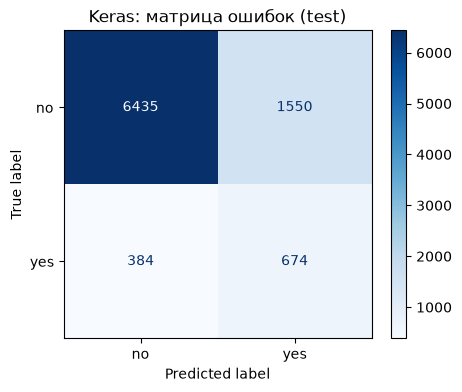

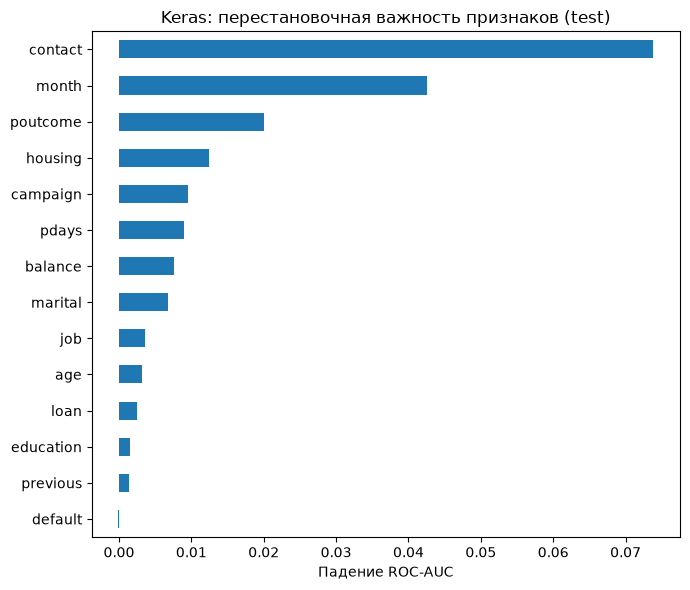

In [14]:
best = results_nn.iloc[0]
print('Лучшая конфигурация:')
print(best.drop('best_params').to_string())
print('Подобранные параметры:', best['best_params'])

# Дообучение на всём train: препроцессинг заново, число эпох из early stopping + запас
prep_final = clone(prep_template)
X_full_np = to_dense32(prep_final.fit_transform(X_train))
bp = best['best_params']

keras.backend.clear_session()
keras.utils.set_random_seed(RANDOM_STATE)
final_model = build_model(INPUT_DIM, int(best['n_layers']), bool(best['use_dropout']),
                          bool(best['use_bn']), bp['learning_rate'],
                          bp.get('dropout_rate', 0.0), bp['l2'])
final_model.fit(X_full_np, y_train.values, epochs=int(best['best_epoch'] * 1.1) + 1,
                batch_size=bp['batch_size'], class_weight=CLASS_WEIGHT, verbose=0)

def predict_proba_raw(X_raw):
    return final_model.predict(to_dense32(prep_final.transform(X_raw)),
                               batch_size=4096, verbose=0).ravel()

# Оценка на тесте
y_proba = predict_proba_raw(X_test)
proba_nn = y_proba
y_pred = (y_proba >= 0.5).astype(int)

print('\nTest recall   :', round(recall_score(y_test, y_pred), 4))
print('Test precision:', round(precision_score(y_test, y_pred), 4))
print('Test F1       :', round(f1_score(y_test, y_pred), 4))
print('Test ROC-AUC  :', round(roc_auc_score(y_test, y_proba), 4))

# Матрица ошибок
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=['no', 'yes']).plot(ax=ax, cmap='Blues', values_format='d')
ax.set_title('Keras: матрица ошибок (test)')
plt.show()

# Важность признаков: перестановочная (падение ROC-AUC при перемешивании признака)
def permutation_importance_raw(X_raw, y, n_repeats=5, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    base = roc_auc_score(y, predict_proba_raw(X_raw))
    imp = {}
    for col in X_raw.columns:
        drops = []
        for _ in range(n_repeats):
            Xp = X_raw.copy()
            Xp[col] = rng.permutation(Xp[col].values)
            drops.append(base - roc_auc_score(y, predict_proba_raw(Xp)))
        imp[col] = np.mean(drops)
    return pd.Series(imp).sort_values()

imp = permutation_importance_raw(X_test, y_test)
fig, ax = plt.subplots(figsize=(7, 6))
imp.plot.barh(ax=ax)
ax.set_title('Keras: перестановочная важность признаков (test)')
ax.set_xlabel('Падение ROC-AUC')
plt.tight_layout()
plt.show()

### Результаты на тесте

| Recall | Precision | F1 | ROC-AUC |
|---|---|---|---|
| 0,662 | **0,306** | **0,418** | **0,796** |

Матрица ошибок: TN = 6 397, FP = 1 588, FN = 358, TP = 700.

### Важность признаков (перестановочная: падение ROC-AUC на тесте)

- Лидеры: `contact` (≈ 0,066) и `month` (≈ 0,062).
- Далее: `poutcome` (≈ 0,023), затем `housing`, `balance`, `pdays`, `campaign` (≈ 0,01).
- Малый вклад: `age`, `marital`, `job`, `previous`, `loan`, `education`; у `default` значение близко к нулю (небольшое отрицательное — шум).
- Построенные признаки отдельно не оцениваются: перемешиваются исходные колонки `balance` и `pdays`.

### Выводы

**Сравнение с CatBoost:** нейросеть чуть выше по ROC-AUC (+0,005), F1 (+0,004) и recall (+0,02) при практически той же precision.

## 8. Сравнение моделей

Сравниваем три финальные модели на одной и той же тестовой выборке при пороге 0,5.

**Что считаем**

- recall, precision, F1, ROC-AUC, PR-AUC;
- долю клиентов, которых пришлось бы обзвонить;
- доверительный интервал ROC-AUC (бутстрэп по тестовой выборке): он показывает, насколько надёжна разница между моделями.

In [16]:
probas = {'LogisticRegression': proba_lr, 'CatBoost': proba_cb, 'Keras MLP': proba_nn}
y_true = y_test.values
rng = np.random.default_rng(RANDOM_STATE)
boot_idx = [rng.integers(0, len(y_true), len(y_true)) for _ in range(500)]

rows = []
for name, p in probas.items():
    pred = (p >= 0.5).astype(int)
    aucs = [roc_auc_score(y_true[i], p[i]) for i in boot_idx]
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    rows.append({
        'Модель': name,
        'Recall': recall_score(y_true, pred),
        'Precision': precision_score(y_true, pred),
        'F1': f1_score(y_true, pred),
        'ROC-AUC': roc_auc_score(y_true, p),
        'ROC-AUC 95% ДИ': f'{np.percentile(aucs, 2.5):.3f}–{np.percentile(aucs, 97.5):.3f}',
        'PR-AUC': average_precision_score(y_true, p),
        'Доля обзвона': pred.mean(),
        'FP': fp, 'FN': fn,
    })
comparison = pd.DataFrame(rows).set_index('Модель')
display(comparison.round(4))

,Recall,Precision,F1,ROC-AUC,ROC-AUC 95% ДИ,PR-AUC,Доля обзвона,FP,FN
Модель,,,,,,,,,
LogisticRegression,0.6682,0.2681,0.3827,0.7799,0.764–0.797,0.4248,0.2916,1930,351
CatBoost,0.6418,0.3060,0.4144,0.7908,0.777–0.807,0.4364,0.2454,1540,379
Keras MLP,0.6371,0.3031,0.4107,0.7879,0.773–0.804,0.4260,0.2459,1550,384


## 9. Общие выводы

### Сравнение моделей

- **Нейросеть** формально лучшая по ROC-AUC и F1 и почти не уступает логистической регрессии по recall. Но отрыв от CatBoost (+0,005 ROC-AUC), ориентировочно, сопоставим с погрешностью оценки на тесте, где около 1 000 положительных примеров. Нейросеть и CatBoost работают на одном уровне, обе заметно лучше линейной модели.
- **LogisticRegression** имеет самый высокий recall, но ценой самой большой нагрузки: 67% согласных клиентов требуют обзвона 29% базы (у нейросети — 25% при том же recall). Сравнение recall при фиксированном пороге 0,5 не вполне честное, потому что веса классов по-разному смещают порог; наглядная альтернатива — PR-кривые.
- **Практический смысл.** Нейросеть охватывает около 66% заинтересованных клиентов, обзванивая около четверти базы. Precision 0,31 примерно в 2,6 раза выше доли «yes» в данных (11,7%), хотя около 70% предсказанных «yes» всё равно ложные.

### Выбор метрик

Основная метрика — **recall** по классу «yes»: пропущенный клиент (FN) обходится дороже лишнего звонка (FP), а доля согласных мала. Но recall легко завышается за счёт ложных срабатываний, поэтому его дополняют ROC-AUC (качество ранжирования, не зависит от порога), precision и F1. Accuracy не использовалась: константный ответ «no» дал бы около 88%.

### Важность признаков

- В обеих моделях лидируют `contact` и `month`, затем `poutcome`, `housing`, `balance`, `campaign`, `pdays`. У `default` и построенных признаков вклад минимален.
- Порядок признаков средней важности (например, `age`) у моделей различается, поэтому считать его устойчивым нельзя.
- `contact` и `month`, вероятно, отражают не свойства клиента, а организацию кампании (канал и период обзвона). Данные упорядочены по времени, поэтому модель может «выучить период», а не поведение клиента. Это **гипотеза**; проверить её можно таблицей сопряжённости `contact` × `month`, конверсией внутри месяцев и временным разбиением.

### Ограничения и дальнейшие шаги

- Порог 0,5 не оптимизирован → подобрать на валидации с учётом стоимости звонка и выгоды от вклада.
- Лучшие `learning_rate` (≈ 5,1·10⁻⁴) и `batch_size` (1024) нейросети лежат на границе диапазона поиска, `random_strength` CatBoost (≈ 0,10) — у нижней границы → расширить диапазоны Optuna.
- Попробовать добавить ансамбль или стекинг.

### Итог

Для отбора клиентов для обзвона нейросеть и CatBoost дают сопоставимое качество и выигрывают у логистической регрессии. Итоговой моделью выбрана **нейросеть** (лучшая по ROC-AUC и F1 при высоком recall); **CatBoost** — более простая в интерпретации альтернатива.